<a href="https://colab.research.google.com/github/gokulvasan1011/sms_spam_prediction/blob/main/sms_spam_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 0. Imports and reproducibility
import re, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED)

In [5]:
# TASK 1. Load data, handle missing values, build ~2000-message subset
df = pd.read_csv("spam_sms.csv", encoding="utf-8")
df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"})

print("Raw shape         :", df.shape)
print("Missing values    :\n", df.isna().sum())

df = df.dropna(subset=["label", "text"])            # drop rows with a missing label/text
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]                           # drop empty messages
print("Duplicate rows    :", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)    # duplicates would leak between train/test

df["y"] = (df["label"] == "spam").astype(int)       # ham = 0, spam = 1
print("After cleaning    :", df.shape, df["label"].value_counts().to_dict())

# Stratified subset of 2000 messages (keeps the natural ham/spam ratio)
df, _ = train_test_split(df, train_size=2000, stratify=df["y"], random_state=SEED)
df = df.reset_index(drop=True)
print("Subset            :", df.shape, df["label"].value_counts().to_dict())


def clean_text(t: str) -> str:
    t = t.lower()
    t = re.sub(r"(http\S+|www\.\S+)", " url ", t)   # links -> token 'url'
    t = re.sub(r"\d+", " num ", t)                  # any number/phone/price -> 'num'
    t = re.sub(r"[^a-z\s]", " ", t)                 # strip punctuation/symbols/emoji
    return re.sub(r"\s+", " ", t).strip()


df["clean"] = df["text"].apply(clean_text)
print(df[["text", "clean"]].head(3).to_string())

Raw shape         : (5572, 2)
Missing values    :
 label    0
text     0
dtype: int64
Duplicate rows    : 414
After cleaning    : (5158, 3) {'ham': 4516, 'spam': 642}
Subset            : (2000, 3) {'ham': 1751, 'spam': 249}
                                                                                                                                   text                                                                                                                                 clean
0                                                                                               Aight ill get on fb in a couple minutes                                                                                               aight ill get on fb in a couple minutes
1                                                                                                           I havent add Ì_ yet right..                                                                                                     

In [6]:
# TASK 2. Tokenize -> integer sequences -> padding
# Split FIRST so the vocabulary is built on training data only (no leakage).
train_val, test = train_test_split(df, test_size=0.20, stratify=df["y"], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.125, stratify=train_val["y"], random_state=SEED)
print(f"train={len(train)}  val={len(val)}  test={len(test)}")   # 1400 / 200 / 400

PAD, OOV = 0, 1
VOCAB_SIZE = 5000
counts = Counter(w for t in train["clean"] for w in t.split())
word_index = {w: i + 2 for i, (w, _) in enumerate(counts.most_common(VOCAB_SIZE - 2))}
print("Unique training words:", len(counts), "| vocab used:", len(word_index) + 2)

lens = train["clean"].str.split().str.len()
MAX_LEN = 50                                         # covers ~99% of messages
print(f"Token length mean={lens.mean():.1f}, 95th pct={lens.quantile(.95):.0f}, "
      f"99th pct={lens.quantile(.99):.0f} -> MAX_LEN={MAX_LEN}")


def encode(texts, maxlen=MAX_LEN):
    """words -> ids (OOV=1), then pre-pad with 0 / truncate to maxlen."""
    out = np.zeros((len(texts), maxlen), dtype="int32")
    for i, t in enumerate(texts):
        ids = [word_index.get(w, OOV) for w in t.split()][:maxlen]
        if ids:
            out[i, -len(ids):] = ids                 # 'pre' padding, like Keras default
    return out


X_train, X_val, X_test = (encode(d["clean"]) for d in (train, val, test))
y_train, y_val, y_test = (d["y"].values for d in (train, val, test))
print("X_train:", X_train.shape, "| example:", X_train[0][-12:])

train=1400  val=200  test=400
Unique training words: 3667 | vocab used: 3669
Token length mean=16.0, 95th pct=35, 99th pct=46 -> MAX_LEN=50
X_train: (1400, 50) | example: [ 35  22   2  28  70   2  87 239 813 478 814 417]


In [7]:
# TASK 3. Model: GRU (justification at the bottom of the file)
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.keras.utils.set_random_seed(SEED)

EMB_DIM = 64
model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, EMB_DIM, mask_zero=True),   # learn word vectors, ignore padding
    layers.GRU(64, dropout=0.2, recurrent_dropout=0.0),      # recurrent_dropout=0 keeps cuDNN fast path
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),                   # P(spam)
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,073 (1.32 MB)

 Trainable params: 347,073 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

class_weight: {0: np.float64(0.5709624796084829), 1: np.float64(4.022988505747127)}
Epoch 1/30
44/44 - 12s - 275ms/step - accuracy: 0.7036 - loss: 0.5819 - val_accuracy: 0.9600 - val_loss: 0.3299
Epoch 2/30
44/44 - 3s - 71ms/step - accuracy: 0.9579 - loss: 0.1790 - val_accuracy: 0.9750 - val_loss: 0.1209
Epoch 3/30
44/44 - 3s - 65ms/step - accuracy: 0.9864 - loss: 0.0614 - val_accuracy: 0.9700 - val_loss: 0.0767
Epoch 4/30
44/44 - 2s - 45ms/step - accuracy: 0.9936 - loss: 0.0227 - val_accuracy: 0.9850 - val_loss: 0.0660
Epoch 5/30
44/44 - 2s - 42ms/step - accuracy: 0.9979 - loss: 0.0078 - val_accuracy: 0.9850 - val_loss: 0.0657
Epoch 6/30
44/44 - 3s - 61ms/step - accuracy: 0.9993 - loss: 0.0036 - val_accuracy: 0.9900 - val_loss: 0.0679
Epoch 7/30
44/44 - 4s - 81ms/step - accuracy: 0.9993 - loss: 0.0023 - val_accuracy: 0.9900 - val_loss: 0.0701
Epoch 8/30
44/44 - 2s - 45ms/step - accuracy: 0.9993 - loss: 0.0020 - val_accuracy: 0.9900 - val_loss: 0.0722
Epoch 9/30
44/44 - 2s - 42ms/step 

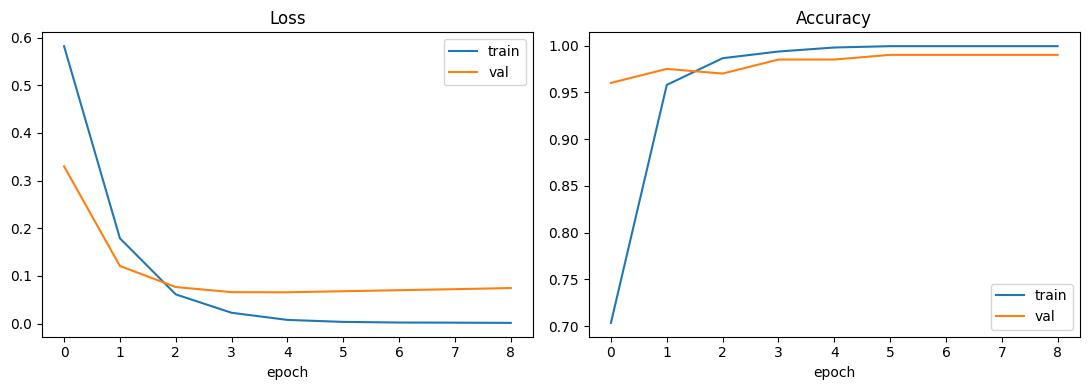

Accuracy : 0.9925
Precision: 0.9796   (of messages flagged spam, how many were spam)
Recall   : 0.9600   (of real spam, how much was caught)
F1-score : 0.9697

               precision    recall  f1-score   support

         ham     0.9943    0.9971    0.9957       350
        spam     0.9796    0.9600    0.9697        50

    accuracy                         0.9925       400
   macro avg     0.9869    0.9786    0.9827       400
weighted avg     0.9925    0.9925    0.9925       400



In [8]:
# TASK 4a. Train (class weights handle the ~87/13 imbalance)
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("class_weight:", class_weight)

early = callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=30, batch_size=32, class_weight=class_weight,
                    callbacks=[early], verbose=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

# %% ------------------------------------------------------------------
# TASK 4b. Evaluate on the held-out test set
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}   (of messages flagged spam, how many were spam)")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}   (of real spam, how much was caught)")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print("\n", classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4))

In [9]:
# TASK 5b. Predictions on unseen SMS messages
def predict_sms(msgs, threshold=0.5):
    p = model.predict(encode([clean_text(m) for m in msgs]), verbose=0).ravel()
    for m, pr in zip(msgs, p):
        print(f"[{'SPAM' if pr >= threshold else 'HAM ':4}] P(spam)={pr:.3f} | {m}")


new_messages = [
    "Congratulations! You have won a $1000 Walmart gift card. Call 09061701461 now to claim your prize",
    "URGENT! Your mobile number has been selected for a free 2000 cash award. Text WIN to 80082",
    "FreeMsg: Get a free ringtone! Reply YES to subscribe, std charges apply. Stop to opt out",
    "Your bank account is locked. Verify now at www.secure-bank-login.com to avoid suspension",
    "Hey, are we still meeting for lunch at 1pm today?",
    "Can you send me the notes from yesterday's class? I missed the last lecture",
    "Mom called, she says dinner is at 8. Don't be late da",
    "Reminder: your dentist appointment is tomorrow at 10am. Please confirm by replying Y",
]
predict_sms(new_messages)

[SPAM] P(spam)=1.000 | Congratulations! You have won a $1000 Walmart gift card. Call 09061701461 now to claim your prize
[SPAM] P(spam)=1.000 | URGENT! Your mobile number has been selected for a free 2000 cash award. Text WIN to 80082
[SPAM] P(spam)=1.000 | FreeMsg: Get a free ringtone! Reply YES to subscribe, std charges apply. Stop to opt out
[HAM ] P(spam)=0.230 | Your bank account is locked. Verify now at www.secure-bank-login.com to avoid suspension
[HAM ] P(spam)=0.001 | Hey, are we still meeting for lunch at 1pm today?
[HAM ] P(spam)=0.000 | Can you send me the notes from yesterday's class? I missed the last lecture
[HAM ] P(spam)=0.001 | Mom called, she says dinner is at 8. Don't be late da
[HAM ] P(spam)=0.035 | Reminder: your dentist appointment is tomorrow at 10am. Please confirm by replying Y


In [10]:
# %% 1. Extra imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.metrics import (confusion_matrix, roc_curve, auc, precision_recall_curve,
                             average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, classification_report)
sns.set_theme(style="whitegrid")

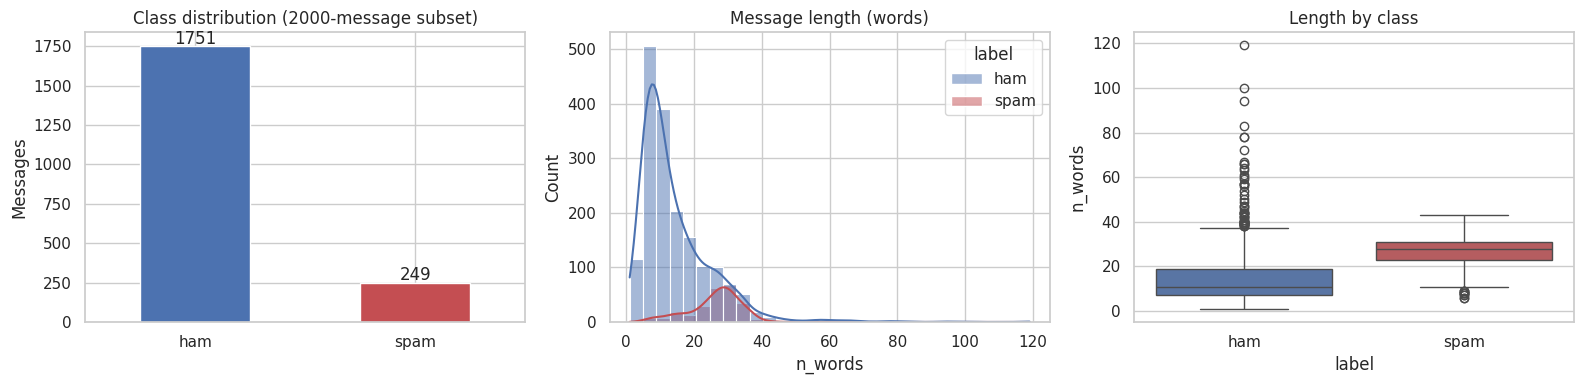

In [11]:
# %% 2. Dataset EDA: class balance + message length
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df["label"].value_counts().plot(kind="bar", color=["#4C72B0", "#C44E52"], ax=ax[0])
ax[0].set_title("Class distribution (2000-message subset)")
ax[0].set_xlabel(""); ax[0].set_ylabel("Messages"); ax[0].tick_params(axis="x", rotation=0)
for i, v in enumerate(df["label"].value_counts().values):
    ax[0].text(i, v + 15, str(v), ha="center")

df["n_words"] = df["clean"].str.split().str.len()
sns.histplot(data=df, x="n_words", hue="label", bins=30, kde=True, ax=ax[1],
             palette={"ham": "#4C72B0", "spam": "#C44E52"})
ax[1].set_title("Message length (words)")

sns.boxplot(data=df, x="label", y="n_words", hue="label", ax=ax[2],
            palette={"ham": "#4C72B0", "spam": "#C44E52"}, legend=False)
ax[2].set_title("Length by class")
plt.tight_layout(); plt.savefig("eda_overview.png", dpi=150); plt.show()

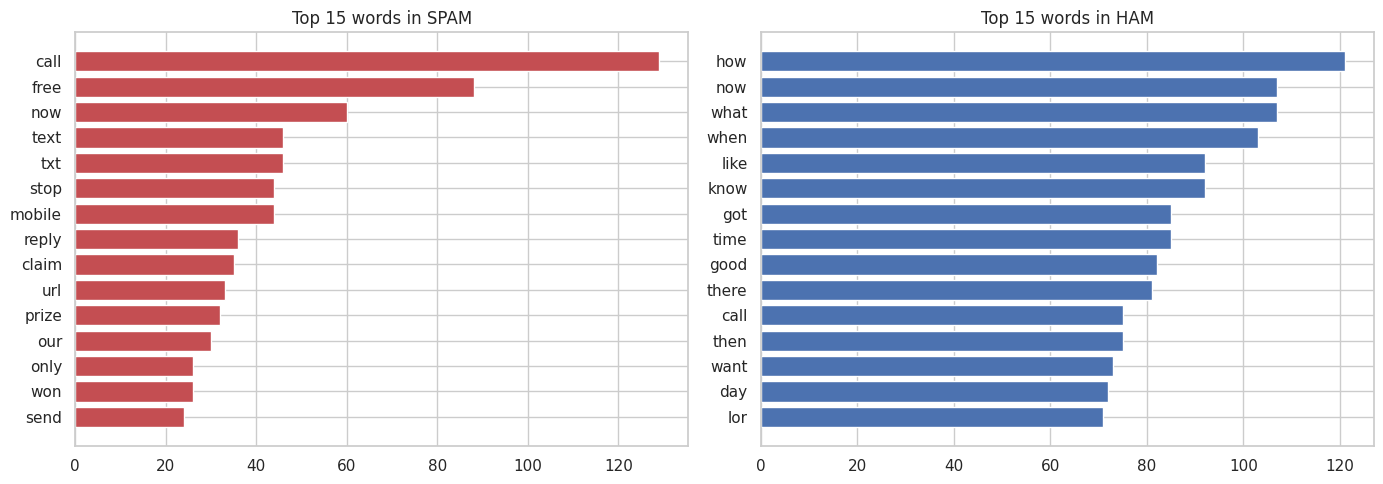

In [12]:
STOP = {"the", "and", "you", "for", "are", "that", "have", "but", "not", "with", "can",
        "will", "this", "was", "your", "num", "from", "get", "just", "its", "out", "all"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, lab, col in zip(ax, ["spam", "ham"], ["#C44E52", "#4C72B0"]):
    c = Counter(w for t in df[df.label == lab]["clean"] for w in t.split()
                if len(w) > 2 and w not in STOP)
    words, freq = zip(*c.most_common(15))
    a.barh(words[::-1], freq[::-1], color=col)
    a.set_title(f"Top 15 words in {lab.upper()}")
plt.tight_layout(); plt.savefig("top_words.png", dpi=150); plt.show()

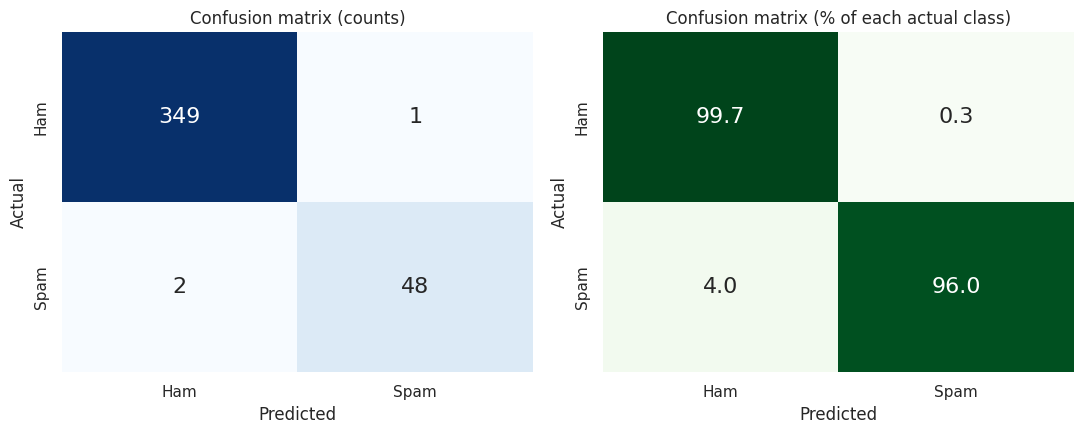

TN=349  FP=1 (genuine SMS blocked)  FN=2 (spam missed)  TP=48


In [15]:
# %% 6. Confusion matrix: counts + row-normalised (percent) heatmaps
cm = confusion_matrix(y_test, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = ["Ham", "Spam"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=labels, yticklabels=labels, annot_kws={"size": 16})
ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Greens", cbar=False, ax=ax[1],
            xticklabels=labels, yticklabels=labels, annot_kws={"size": 16})
ax[1].set_title("Confusion matrix (% of each actual class)")
for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp} (genuine SMS blocked)  FN={fn} (spam missed)  TP={tp}")

In [22]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def check_sms(text, threshold=0.5):
    p = float(model.predict(encode([clean_text(text)]), verbose=0)[0][0])
    label = "SPAM 🚨" if p >= threshold else "HAM ✅ (not spam)"
    print(f"Message    : {text}")
    print(f"Prediction : {label}")
    print(f"P(spam)    : {p:.3f}   |   P(ham): {1 - p:.3f}")

box = widgets.Textarea(placeholder="Type or paste an SMS here...",
                       layout=widgets.Layout(width="600px", height="80px"))
btn = widgets.Button(description="Check SMS", button_style="primary")
out = widgets.Output()

def on_click(_):
    with out:
        clear_output()
        if box.value.strip():
            check_sms(box.value)
        else:
            print("Please type something.")

btn.on_click(on_click)
display(box, btn, out)

Textarea(value='', layout=Layout(height='80px', width='600px'), placeholder='Type or paste an SMS here...')

Button(button_style='primary', description='Check SMS', style=ButtonStyle())

Output()